# Analyse prescriptive : combien coûtent les annulations et que peut-on y faire ?
## Hotel Booking Demand, complément de l'évaluation sommative 2

**Étudiant :** Yacine Lezoul

---

### Objectif
Le notebook `01_pipeline.ipynb` répond à la question **« quelle réservation risque d'être annulée ? »**. Celui-ci répond à **« combien cela coûte-t-il et que faut-il faire ? »** :

1. Quand les clients annulent-ils ?
2. Quelle part des chambres annulées l'hôtel parvient-il à revendre ?
3. Quel est le manque à gagner brut et net ?
4. Peut-on tester l'effet d'un acompte avec ces données ?
5. Que rapporterait un acompte, selon son niveau ?
6. Quelle action mener pour chaque réservation ?
7. Combien de réservations accepter au-delà de la capacité ?

### Principe : aucun chiffre inventé
Toutes les grandeurs sont **calculées à partir des données**. Seuls les **niveaux d'acompte** sont des choix de l'hôtel, présentés comme des scénarios. Ce qu'on ne peut pas mesurer (combien de clients fidèles renonceraient devant un acompte) est remplacé par un **seuil de rentabilité** : le taux de fuite maximal acceptable.

### Où se trouve le code
| Fichier | Contenu |
|---|---|
| `src/prescriptive.py` | délais d'annulation, taux de revente, manque à gagner, scénarios d'acompte, seuils, surréservation |
| `src/sauvegarde.py` | chargement du pipeline entraîné par `01_pipeline.ipynb` |
| `src/data_loader.py` | chargement et nettoyage (même séparation entraînement / test que le notebook 01) |

**Prérequis :** avoir exécuté `01_pipeline.ipynb`, qui enregistre le pipeline dans `models/`.

### Remarque sur la fuite de données
Cette analyse utilise `reservation_status_date` (date d'annulation), exclue du modèle prédictif car connue seulement après coup. Ici, c'est légitime : on fait un **bilan** de ce qui s'est passé, pas une prédiction.

In [1]:
# ---------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------
import sys
import warnings
from pathlib import Path
from typing import cast

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn import set_config

set_config(transform_output="pandas", display="text")
sns.set_theme(style="whitegrid", palette="deep")

from src import config
from src import data_loader as dl
from src import prescriptive as pr
from src.sauvegarde import load_metadata, load_pipeline

# Sections 1 à 3 (bilan financier) : TOUTES les réservations, doublons compris.
# Deux lignes identiques sont souvent deux vraies chambres d'un même groupe :
# pour compter des chambres et de l'argent, chaque ligne compte.
toutes = pr.load_all_bookings()

# Sections 4 à 7 (modèle) : données nettoyées SANS doublons, mêmes lignes et même
# séparation que le notebook 01, en gardant les colonnes de statut (bilan après coup).
df = pr.add_dates(dl.clean_data(dl.load_raw_data(), verbose=False, drop_leakage=False))

print(f"Réservations, doublons compris (sections 1 à 3) : {len(toutes)}")
print(f"Réservations sans doublons (sections 4 à 7)     : {len(df)}")
print(f"Période d'arrivée : du {toutes['arrival_date'].min():%d/%m/%Y} au {toutes['arrival_date'].max():%d/%m/%Y}")

Réservations, doublons compris (sections 1 à 3) : 119208
Réservations sans doublons (sections 4 à 7)     : 85982
Période d'arrivée : du 01/07/2015 au 31/08/2017


---
## 1. Quand les clients annulent-ils ?
On mesure le **délai entre l'annulation et la date d'arrivée prévue**, réparti en 5 tranches. Seules les réservations **sans dépôt** sont étudiées : ce sont celles pour lesquelles l'hôtel ne récupère rien. Les doublons sont conservés : pour un bilan financier, chaque chambre compte.

In [2]:
timing = pr.cancellation_timing(toutes)
timing.style.format({
    "part_annulations": "{:.1%}", "part_groupes": "{:.1%}",
    "nuitees": "{:,.0f}", "revenu_brut": "{:,.0f} €",
})

,annulations,part_annulations,part_groupes,nuitees,revenu_brut
delay_category,,,,,
moins d'une semaine,5411,18.2%,11.6%,"16,589","1,700,924 €"
1 semaine à 1 mois,8257,27.8%,11.2%,"28,880","3,340,556 €"
1 à 2 mois,5337,18.0%,8.2%,"20,491","2,367,665 €"
2 à 3 mois,3084,10.4%,10.6%,"13,498","1,550,795 €"
plus de 3 mois,7580,25.5%,8.7%,"35,143","4,142,961 €"


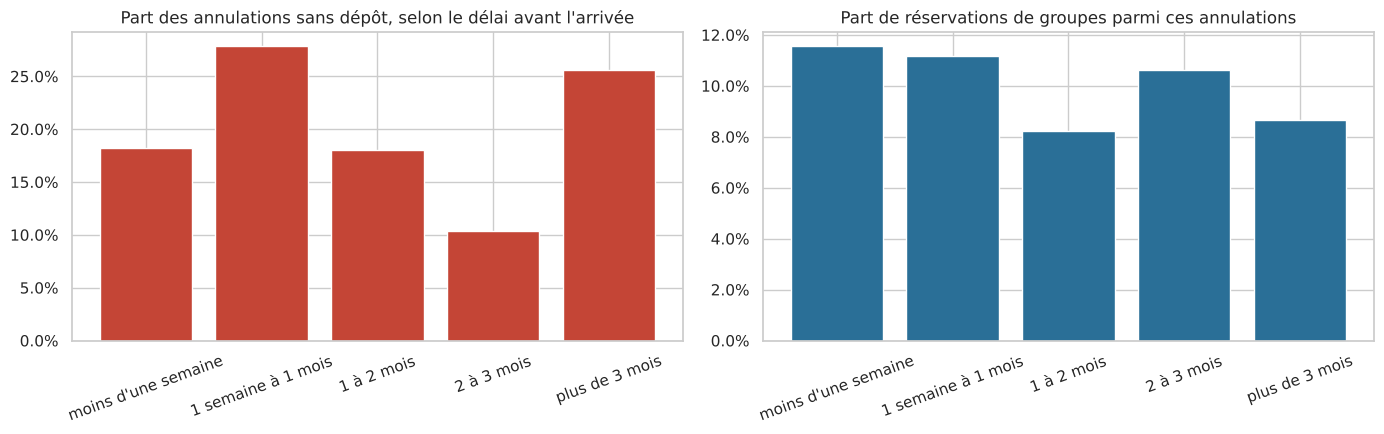

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(timing.index.astype(str), timing["part_annulations"], color="#c44536")
ax[0].set_title("Part des annulations sans dépôt, selon le délai avant l'arrivée")
ax[0].yaxis.set_major_formatter(PercentFormatter(1))
ax[1].bar(timing.index.astype(str), timing["part_groupes"], color="#2a6f97")
ax[1].set_title("Part de réservations de groupes parmi ces annulations")
ax[1].yaxis.set_major_formatter(PercentFormatter(1))
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "delais_annulation.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** les annulations sans dépôt (29 669 réservations entre juillet 2015 et août 2017) se répartissent ainsi :

- **près de la moitié (46 %) ont lieu dans le dernier mois** avant l'arrivée : 18,2 % dans la dernière semaine et 27,8 % entre une semaine et un mois ;
- 18 % entre 1 et 2 mois, 10 % entre 2 et 3 mois ;
- un quart (25,5 %) plus de 3 mois à l'avance.

La part de réservations de groupes reste comprise entre 8 et 12 % dans toutes les tranches. Avec ce découpage en 5 tranches, on ne voit donc pas de concentration des groupes dans les annulations très anticipées : l'effet observé au-delà de 6 mois est dilué dans la tranche « plus de 3 mois ».

---
## 2. Quelle part des chambres annulées est revendue ?

**Méthode** (fonction `estimate_resale()`) :
1. Pour chaque nuit et chaque hôtel, on compte les chambres **réellement occupées** (séjours réalisés).
2. La capacité de l'hôtel, absente des données, est estimée par le **99e centile** de l'occupation observée.
3. Une nuit donnée, les chambres annulées sont **perdues** dans la limite des chambres restées vides ; le reste est considéré comme **revendu** :
   `perdues = min(chambres annulées, capacité - occupation)`.
4. Chaque annulation reçoit la moyenne des taux de revente de ses nuits, puis on fait la moyenne par tranche de délai (pondérée par le revenu du séjour).

Pour compter les chambres, on utilise les données **avec doublons** : deux lignes identiques peuvent être deux vraies chambres réservées par un même groupe.

In [4]:
annulations, capacite, nuits = pr.estimate_resale()
print("Capacité estimée (chambres) :", capacite.to_dict())

revente = pr.resale_by_delay(annulations)
revente.to_frame().style.format("{:.1%}")

Capacité estimée (chambres) : {'City Hotel': 224.0, 'Resort Hotel': 184.0}


,taux_revente
delay_category,
moins d'une semaine,61.0%
1 semaine à 1 mois,71.1%
1 à 2 mois,77.1%
2 à 3 mois,80.6%
plus de 3 mois,86.2%


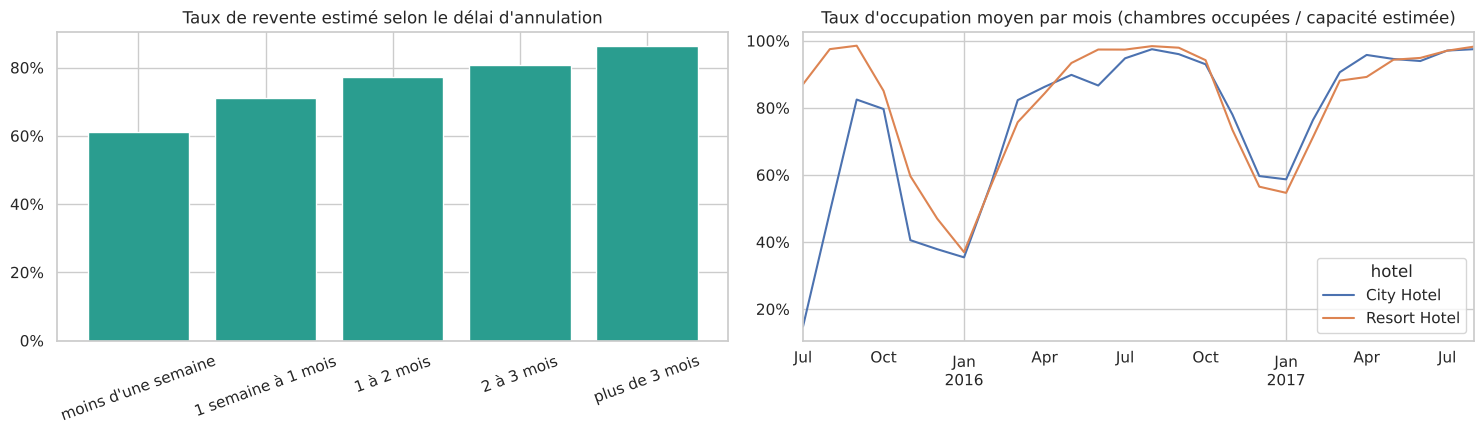

In [5]:
# Taux d'occupation moyen par mois et par hôtel (occupation réelle / capacité estimée)
occ = nuits.reset_index()
occ["taux_occupation"] = occ["occupees"] / occ["capacite"]
occ["mois"] = occ["night"].dt.to_period("M").dt.to_timestamp()
mensuel = occ.groupby(["hotel", "mois"])["taux_occupation"].mean().unstack(0)
# Septembre 2017 ne contient que les dernières nuits des séjours arrivés fin août : mois retiré du graphique
mensuel = mensuel.loc[:"2017-08-01"]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(revente.index.astype(str), revente.values, color="#2a9d8f")
ax[0].set_title("Taux de revente estimé selon le délai d'annulation")
ax[0].yaxis.set_major_formatter(PercentFormatter(1))
ax[0].tick_params(axis="x", rotation=20)
mensuel.plot(ax=ax[1])
ax[1].set_title("Taux d'occupation moyen par mois (chambres occupées / capacité estimée)")
ax[1].yaxis.set_major_formatter(PercentFormatter(1))
ax[1].set_xlabel("")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "revente_occupation.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** plus l'annulation est tardive, moins la chambre est revendue :

- **61 %** de revente pour une annulation dans la dernière semaine ;
- **71 %** entre une semaine et un mois ;
- **77 %** entre 1 et 2 mois, **81 %** entre 2 et 3 mois ;
- **86 %** au-delà de 3 mois.

La progression est régulière et cohérente : plus l'hôtel est prévenu tôt, plus il a de temps pour relouer. Le graphique d'occupation montre aussi une forte saisonnalité, avec des pics en été. Une annulation en basse saison est donc plus difficile à compenser.

**Limites de la méthode :**
- La capacité est une estimation (224 et 184 chambres).
- Toutes les annulations d'une même nuit reçoivent le même taux de revente.
- Le taux est plutôt surestimé si l'hôtel pratiquait déjà la surréservation, car une nuit « pleine » peut l'être grâce à elle.
- Les bords de la période sont incomplets (juillet 2015 pour le City Hotel, qui n'occupe en moyenne que 33 chambres ce mois-là). Une vérification en excluant le premier et le dernier mois change les taux de moins d'un point : les estimations sont donc robustes.

---
## 3. Manque à gagner brut et net
- **Brut** : valeur des séjours annulés (tarif x nuits).
- **Net** : brut x (1 - taux de revente de la tranche) : ce que l'hôtel a réellement perdu.

In [6]:
pertes = pr.loss_table(timing, revente)
realise = toutes.loc[toutes["is_canceled"] == 0, "stay_revenue"].sum()

display(pertes[["annulations", "revenu_brut", "taux_revente", "perte_nette", "part_perte_nette"]].style.format({
    "revenu_brut": "{:,.0f} €", "taux_revente": "{:.1%}", "perte_nette": "{:,.0f} €", "part_perte_nette": "{:.1%}",
}))
print(f"Manque à gagner brut  : {pertes['revenu_brut'].sum():>12,.0f} €")
print(f"Manque à gagner net   : {pertes['perte_nette'].sum():>12,.0f} €")
print(f"Revenu des séjours réalisés (même période) : {realise:,.0f} €")
print(f"Perte nette / revenu réalisé : {pertes['perte_nette'].sum() / realise:.1%}")

,annulations,revenu_brut,taux_revente,perte_nette,part_perte_nette
delay_category,,,,,
moins d'une semaine,5411,"1,700,924 €",61.0%,"663,948 €",21.8%
1 semaine à 1 mois,8257,"3,340,556 €",71.1%,"965,127 €",31.7%
1 à 2 mois,5337,"2,367,665 €",77.1%,"541,508 €",17.8%
2 à 3 mois,3084,"1,550,795 €",80.6%,"300,540 €",9.9%
plus de 3 mois,7580,"4,142,961 €",86.2%,"571,563 €",18.8%


Manque à gagner brut  :   13,102,902 €
Manque à gagner net   :    3,042,685 €
Revenu des séjours réalisés (même période) : 25,986,976 €
Perte nette / revenu réalisé : 11.7%


**Interprétation :**

- **Manque à gagner brut : 13,1 M€** en un peu plus de deux ans, soit la moitié du revenu réalisé (26,0 M€). Ce chiffre surestime fortement la perte réelle.
- **Manque à gagner net, après revente : 3,0 M€**, soit **11,7 % du revenu réalisé**. C'est la perte réelle à combattre.
- **Les annulations du dernier mois concentrent 53 % de la perte nette** (0,66 M€ pour la dernière semaine, 0,97 M€ entre une semaine et un mois), alors qu'elles ne représentent que 46 % des annulations. Rapportée au revenu du séjour, la perte nette vaut 39 % pour une annulation dans la dernière semaine, contre 14 % au-delà de 3 mois.

**Conséquence pour l'acompte :** c'est l'annulation **tardive** qu'il faut viser. Un acompte remboursable jusqu'à 30 jours avant l'arrivée cible précisément cette perte, sans pénaliser les clients qui annulent tôt (et dont la chambre se revend à 86 %).

---
## 4. Peut-on tester l'effet d'un acompte avec ces données ?

### 4.1 Test du chi-deux : dépôt et annulation sont-ils liés ?
- H0 : le taux d'annulation est indépendant du type de dépôt.
- H1 : il en dépend.

In [7]:
from scipy.stats import chi2_contingency

tableau = pd.crosstab(df["deposit_type"], df["is_canceled"])
chi2, p_valeur, ddl, _ = chi2_contingency(tableau)
display(tableau.assign(taux_annulation=tableau[1] / tableau.sum(axis=1)).round(3))
print(f"Chi-deux = {chi2:,.0f}, degrés de liberté = {ddl}, p-valeur = {p_valeur:.2e}")

is_canceled,0,1,taux_annulation
deposit_type,,,
No Deposit,62145,22731,0.268
Non Refund,52,958,0.949
Refundable,70,26,0.271


Chi-deux = 2,315, degrés de liberté = 2, p-valeur = 0.00e+00


### 4.2 Qui sont les réservations non remboursables ?

In [8]:
nr = df[df["deposit_type"] == "Non Refund"]
print(f"Réservations non remboursables : {len(nr)}")
print("Pays principaux     :", nr["country"].value_counts().head(3).to_dict())
print("Agents principaux   :", nr["agent"].value_counts().head(3).to_dict())
print("Segments principaux :", nr["market_segment"].value_counts().head(3).to_dict())

# Comparaison à segment égal : taux d'annulation et effectif par type de dépôt
par_segment = df.pivot_table(index="market_segment", columns="deposit_type", values="is_canceled",
                             aggfunc=["mean", "size"]).round(3)
par_segment

Réservations non remboursables : 1010
Pays principaux     : {'PRT': 958, 'GBR': 14, 'DEU': 11}
Agents principaux   : {1.0: 278, 3.0: 42, 229.0: 36}
Segments principaux : {'Groups': 638, 'Offline TA/TO': 282, 'Corporate': 63}


mean                             size             \
deposit_type   No Deposit Non Refund Refundable No Deposit Non Refund   
market_segment                                                          
Aviation            0.199        NaN        NaN      226.0        NaN   
Complementary       0.124        NaN        NaN      685.0        NaN   
Corporate           0.111      0.698      0.333     4048.0       63.0   
Direct              0.146      0.667      0.333    11714.0        9.0   
Groups              0.167      0.962      0.101     3727.0      638.0   
Offline TA/TO       0.130      0.989      0.500    13177.0      282.0   
Online TA           0.353      0.833      1.000    51297.0       18.0   
Undefined           1.000        NaN        NaN        2.0        NaN   

                           
deposit_type   Refundable  
market_segment             
Aviation              NaN  
Complementary         NaN  
Corporate             3.0  
Direct                6.0  
Groups               69.0  
Offline TA/TO         4.0  
Online TA            14.0  
Undefined             NaN

**Interprétation :**

- **Le test est très significatif** (chi-deux = 2 315, p < 0,001) : le type de dépôt et l'annulation sont liés. **Mais dans le mauvais sens** : 95 % des réservations non remboursables sont annulées, contre 27 % sans dépôt.
- **Ce n'est pas l'acompte qui provoque l'annulation.** Les 1 010 réservations non remboursables sont presque toutes portugaises (958) et viennent pour beaucoup d'un même agent (278 pour l'agent n° 1) et des segments Groupes (638) et agences hors ligne (282). Ce sont des blocs de réservations libérés en masse. La fiche des données indique de plus qu'elles sont payées en totalité : l'hôtel est donc intégralement compensé.
- **À segment égal, les effectifs sont trop petits** pour conclure : 18 réservations non remboursables chez les agences en ligne, 9 en direct.

**Conclusion :** ces données ne permettent ni de mesurer l'effet dissuasif d'un acompte, ni de savoir combien de clients fidèles il ferait fuir (ceux qui renoncent n'apparaissent pas dans le fichier). Seul un test A/B le permettrait : avec les exemples ci-dessous, il faudrait de 109 à 832 réservations par groupe selon l'ampleur de l'effet recherché.

### 4.3 Ce qui permettrait de répondre : un test A/B
Pendant quelques semaines, on demande un acompte à la moitié des réservations à risque élevé, **tirées au hasard**, et pas à l'autre moitié.
- H0 : le taux de réservations confirmées est le même dans les deux groupes.
- H1 : il est plus faible avec acompte (des clients renoncent).

Taille d'échantillon nécessaire par groupe (test unilatéral de deux proportions, risque 5 %, puissance 80 %). Les taux ci-dessous sont **des exemples** pour illustrer le calcul :

In [9]:
from scipy.stats import norm


def taille_echantillon(p1: float, p2: float, alpha: float = 0.05, puissance: float = 0.80) -> int:
    """Effectif par groupe pour détecter un écart entre deux proportions (test unilatéral)."""
    z_a, z_b = norm.ppf(1 - alpha), norm.ppf(puissance)
    return int(np.ceil((z_a + z_b) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2)) / (p1 - p2) ** 2))


exemples = [(0.95, 0.92), (0.95, 0.90), (0.95, 0.85)]
pd.DataFrame(
    [{"confirmées sans acompte": a, "confirmées avec acompte": b, "réservations par groupe": taille_echantillon(a, b)}
     for a, b in exemples]
)

,confirmées sans acompte,confirmées avec acompte,réservations par groupe
0,0.95,0.92,832
1,0.95,0.90,341
2,0.95,0.85,109


---
## 5. Que rapporterait un acompte ?

On applique chaque politique d'acompte aux réservations **signalées par le modèle** sur l'ensemble de test (17 197 réservations jamais vues par le modèle, 20 % des données), avec deux seuils choisis dans le notebook 01 :
- **seuil F0,5** (précision prioritaire) : on ne demande un acompte qu'aux réservations les plus sûres ;
- **seuil F2** (rappel prioritaire) : on vise plus large.

Deux règles rendent les deux seuils comparables :
- **la perte de départ est la même pour les deux seuils** : la perte nette de **toutes** les annulations sans dépôt de l'ensemble de test. Le seuil ne change que ce qui est récupéré ;
- **l'acompte n'est demandé qu'aux réservations sans dépôt** : une réservation non remboursable est déjà payée en totalité, une réservation remboursable a déjà versé un dépôt.

Pour chaque politique :
- **perte nette totale** : revenu x (1 - taux de revente de la tranche de délai), sur toutes les annulations sans dépôt ;
- **acompte conservé** : uniquement pour les annulations signalées, et seulement après la date limite si l'acompte est remboursable ;
- **perte nette restante** = perte nette totale - acompte conservé ;
- **clients fidèles exposés** : réservations signalées qui n'ont **pas** été annulées ;
- **taux de fuite maximal acceptable** = acompte conservé / revenu des fidèles exposés. Si une plus grande part des fidèles renonce à réserver, l'acompte coûte plus qu'il ne rapporte.

**Lecture :** l'acompte est conservé même quand la chambre est revendue. La part de la perte couverte peut donc dépasser 100 % : l'hôtel récupère alors plus que ce qu'il perdait. De même, un taux de fuite maximal supérieur à 100 % signifie que l'acompte resterait rentable même si **tous** les fidèles exposés renonçaient.

In [10]:
modele = load_pipeline()
meta = load_metadata()
seuil_f2, seuil_f05 = meta["seuil_f2"], meta["seuil_f05"]

# Même séparation que dans le notebook 01 (même nettoyage, même graine)
X, y = dl.split_features_target(df)
X_train, X_test, y_train, y_test = dl.train_test_data(X, y)
test = df.loc[X_test.index].copy()
test["proba"] = modele.predict_proba(X_test)[:, 1]
print(f"Seuil F0,5 = {seuil_f05:.3f} | seuil F2 = {seuil_f2:.3f}")
print("Politiques comparées :", list(pr.DEPOSIT_POLICIES))

Seuil F0,5 = 0.537 | seuil F2 = 0.171
Politiques comparées : ['Première nuit', '20 % du séjour', '50 % du séjour', "50 %, remboursable jusqu'à 30 jours", "100 %, remboursable jusqu'à 30 jours"]


In [11]:
formats: dict = {  # format d'affichage de chaque colonne
    "perte_nette_totale": "{:,.0f} €", "acompte_conserve": "{:,.0f} €",
    "perte_nette_restante": "{:,.0f} €", "part_perte_couverte": "{:.1%}", "taux_fuite_max_acceptable": "{:.1%}",
}
for nom, seuil in [("F0,5 (précision prioritaire)", seuil_f05), ("F2 (rappel prioritaire)", seuil_f2)]:
    signale = test["proba"] >= seuil
    print(f"\n=== Acompte demandé au-dessus du seuil {nom} = {seuil:.2f} ===")
    display(pr.deposit_scenarios(test, signale, revente).style.format(formats))


=== Acompte demandé au-dessus du seuil F0,5 (précision prioritaire) = 0.54 ===


,reservations_signalees,annulations_signalees,perte_nette_totale,acompte_conserve,perte_nette_restante,part_perte_couverte,fideles_exposes,revenu_fideles_exposes,part_annulations_visees,part_fideles_touches,taux_fuite_max_acceptable
politique,,,,,,,,,,,
Première nuit,3509,2578,"510,203 €","317,259 €","192,944 €",62.2%,931,477834.250000,0.568467,0.074899,66.4%
20 % du séjour,3509,2578,"510,203 €","284,636 €","225,566 €",55.8%,931,477834.250000,0.568467,0.074899,59.6%
50 % du séjour,3509,2578,"510,203 €","711,591 €","-201,388 €",139.5%,931,477834.250000,0.568467,0.074899,148.9%
"50 %, remboursable jusqu'à 30 jours",3509,2578,"510,203 €","224,935 €","285,268 €",44.1%,931,477834.250000,0.568467,0.074899,47.1%
"100 %, remboursable jusqu'à 30 jours",3509,2578,"510,203 €","449,870 €","60,333 €",88.2%,931,477834.250000,0.568467,0.074899,94.1%



=== Acompte demandé au-dessus du seuil F2 (rappel prioritaire) = 0.17 ===


,reservations_signalees,annulations_signalees,perte_nette_totale,acompte_conserve,perte_nette_restante,part_perte_couverte,fideles_exposes,revenu_fideles_exposes,part_annulations_visees,part_fideles_touches,taux_fuite_max_acceptable
politique,,,,,,,,,,,
Première nuit,8489,4208,"510,203 €","507,516 €","2,686 €",99.5%,4281,1921515.930000,0.927894,0.344409,26.4%
20 % du séjour,8489,4208,"510,203 €","420,398 €","89,804 €",82.4%,4281,1921515.930000,0.927894,0.344409,21.9%
50 % du séjour,8489,4208,"510,203 €","1,050,995 €","-540,793 €",206.0%,4281,1921515.930000,0.927894,0.344409,54.7%
"50 %, remboursable jusqu'à 30 jours",8489,4208,"510,203 €","396,175 €","114,028 €",77.7%,4281,1921515.930000,0.927894,0.344409,20.6%
"100 %, remboursable jusqu'à 30 jours",8489,4208,"510,203 €","792,350 €","-282,147 €",155.3%,4281,1921515.930000,0.927894,0.344409,41.2%


**Interprétation (ensemble de test, soit 20 % des réservations) :**

**La perte de départ est la même pour les deux seuils : 510 203 €** de perte nette, sur toutes les annulations sans dépôt de l'ensemble de test. Les deux seuils se comparent donc directement.

**Au seuil F0,5**, 3 509 réservations sans dépôt sont signalées, dont 2 578 annulations et **931 clients fidèles exposés**. Les 204 réservations à dépôt signalées ne reçoivent pas de demande d'acompte (elles sont déjà payées ou ont déjà versé un dépôt).

| Politique | Acompte conservé | Perte restante | Perte couverte | Taux de fuite maximal acceptable |
|---|---|---|---|---|
| 50 %, remboursable jusqu'à 30 jours | 224 935 € | 285 268 € | 44 % | 47 % |
| 20 % du séjour | 284 636 € | 225 566 € | 56 % | 60 % |
| Première nuit | 317 259 € | 192 944 € | 62 % | 66 % |
| 100 %, remboursable jusqu'à 30 jours | 449 870 € | 60 333 € | 88 % | 94 % |
| 50 % du séjour | 711 591 € | gain de 201 388 € | 140 % | 149 % |

**Au seuil F2**, 8 489 réservations sont signalées, dont 4 208 annulations et **4 281 fidèles exposés** (4,6 fois plus). L'acompte récupère davantage, de 78 % à 206 % de la perte nette selon la politique (82 % avec 20 % du séjour, contre 56 % au seuil F0,5). Mais le taux de fuite maximal acceptable tombe entre 21 % et 55 % : il suffirait qu'un fidèle sur cinq renonce pour qu'un acompte de 20 % devienne perdant.

**Ce que ça montre :**

- **Le choix du seuil est un arbitrage** : F2 récupère plus d'argent, mais touche 4,6 fois plus de clients fidèles ; F0,5 récupère moins, mais reste rentable même si une grande part des fidèles renonce. Sans connaître la réaction réelle des clients, F0,5 est le choix prudent pour un acompte, et F2 convient à une relance sans engagement.
- Parce que la plupart des chambres annulées sont revendues, la perte **nette** est faible par rapport au prix du séjour : un acompte modeste en couvre une bonne part. Pour une annulation de dernière minute, la perte nette vaut toutefois 39 % du séjour.
- Avec un acompte de 100 % remboursable jusqu'à 30 jours, les clients qui annulent tôt sont remboursés et l'hôtel couvre 88 % de la perte nette au seuil F0,5. L'acompte reste rentable tant que moins de 94 % des fidèles exposés renoncent.
- Le chiffre qui manque est le taux de fuite réel. Il ne peut venir que d'un test A/B (section 4.3). Au seuil F0,5, ce taux devrait dépasser 47 % à 149 % selon la politique pour que l'acompte devienne perdant.

### 5.1 Comparer les deux seuils sur la même échelle

Les deux seuils ne signalent pas le même nombre de réservations (3 509 contre 8 489) : leurs « taux de fuite maximal acceptable » sont donc calculés sur des groupes différents. Pour comparer sur le même axe :
- **les parts sont rapportées à l'ensemble du test** : part de **toutes** les annulations visées, part de **tous** les clients fidèles touchés ;
- **le gain net est calculé selon la part des fidèles qui renoncent** devant un acompte. Ce taux décrit la réaction des clients, pas le seuil : c'est la même inconnue pour les deux seuils.

Gain net = acompte conservé - taux de fuite x revenu des fidèles touchés (`pr.net_gain_by_leak_rate`). Le **point de bascule** est le taux de fuite pour lequel les deux seuils rapportent autant (`pr.switch_leak_rate`).

,"annulations visées F0,5",annulations visées F2,"fidèles touchés F0,5",fidèles touchés F2,"perte couverte F0,5",perte couverte F2,point de bascule,perdant dès (F2),"perdant dès (F0,5)"
politique,,,,,,,,,
Première nuit,56.8%,92.8%,7.5%,34.4%,62.2%,99.5%,13.2%,26.4%,66.4%
20 % du séjour,56.8%,92.8%,7.5%,34.4%,55.8%,82.4%,9.4%,21.9%,59.6%
50 % du séjour,56.8%,92.8%,7.5%,34.4%,139.5%,206.0%,23.5%,54.7%,148.9%
"50 %, remboursable jusqu'à 30 jours",56.8%,92.8%,7.5%,34.4%,44.1%,77.7%,11.9%,20.6%,47.1%
"100 %, remboursable jusqu'à 30 jours",56.8%,92.8%,7.5%,34.4%,88.2%,155.3%,23.7%,41.2%,94.1%


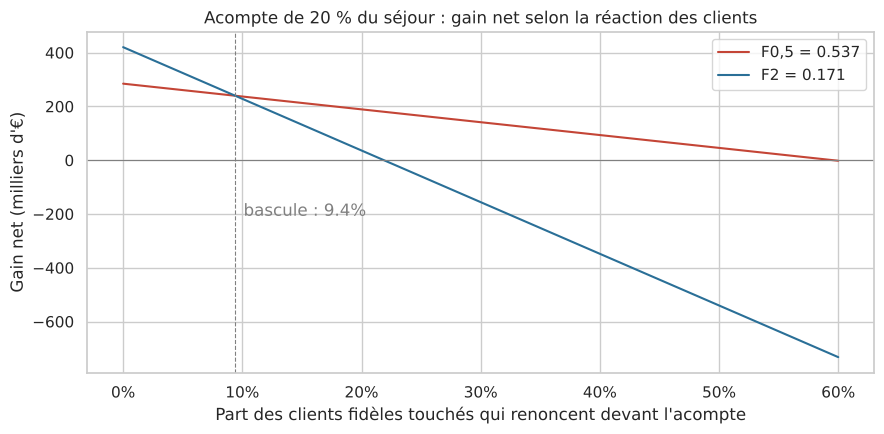

In [12]:
comparaison = []
for politique in pr.DEPOSIT_POLICIES:
    sc_f05 = pr.deposit_scenarios(test, test["proba"] >= seuil_f05, revente).loc[politique]
    sc_f2 = pr.deposit_scenarios(test, test["proba"] >= seuil_f2, revente).loc[politique]
    comparaison.append({
        "politique": politique,
        "annulations visées F0,5": sc_f05["part_annulations_visees"],
        "annulations visées F2": sc_f2["part_annulations_visees"],
        "fidèles touchés F0,5": sc_f05["part_fideles_touches"],
        "fidèles touchés F2": sc_f2["part_fideles_touches"],
        "perte couverte F0,5": sc_f05["part_perte_couverte"],
        "perte couverte F2": sc_f2["part_perte_couverte"],
        "point de bascule": pr.switch_leak_rate(sc_f2, sc_f05),
        "perdant dès (F2)": sc_f2["taux_fuite_max_acceptable"],
        "perdant dès (F0,5)": sc_f05["taux_fuite_max_acceptable"],
    })
comparaison = pd.DataFrame(comparaison).set_index("politique")
display(comparaison.style.format("{:.1%}"))

# Gain net selon la part des fidèles qui renoncent, politique « 20 % du séjour »
taux_fuite = np.linspace(0, 0.6, 61)
sc_f05 = pr.deposit_scenarios(test, test["proba"] >= seuil_f05, revente).loc["20 % du séjour"]
sc_f2 = pr.deposit_scenarios(test, test["proba"] >= seuil_f2, revente).loc["20 % du séjour"]
bascule = pr.switch_leak_rate(sc_f2, sc_f05)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(taux_fuite, pr.net_gain_by_leak_rate(sc_f05, taux_fuite) / 1000, color="#c44536", label=f"F0,5 = {seuil_f05:.3f}")
ax.plot(taux_fuite, pr.net_gain_by_leak_rate(sc_f2, taux_fuite) / 1000, color="#2a6f97", label=f"F2 = {seuil_f2:.3f}")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(bascule, color="grey", ls="--", lw=0.8)
ax.annotate(f"bascule : {bascule:.1%}", (bascule, 0), xytext=(6, -40), textcoords="offset points", color="grey")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Part des clients fidèles touchés qui renoncent devant l'acompte")
ax.set_ylabel("Gain net (milliers d'€)")
ax.set_title("Acompte de 20 % du séjour : gain net selon la réaction des clients")
ax.legend()
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "acompte_bascule.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :**

- **Sur la même base, F2 vise beaucoup plus large** : 93 % de toutes les annulations, contre 57 % au seuil F0,5, mais il demande un acompte à **34,4 % de tous les clients fidèles**, contre 7,5 %.
- **Le meilleur seuil dépend de la réaction des clients.** Avec un acompte de 20 % du séjour, **F2 rapporte plus tant que moins de 9,4 % des fidèles touchés renoncent** ; au-delà, F0,5 rapporte plus. F2 devient perdant dès 22 % de fuite, F0,5 seulement à 60 %.
- Selon la politique, le point de bascule va de 9 % à 24 % : plus l'acompte est élevé, plus F2 garde l'avantage longtemps, parce qu'il récupère beaucoup plus d'argent.

**Conséquence :** sans mesure de la réaction des clients, **F0,5 est le choix prudent** : il rapporte un peu moins si personne ne renonce, mais reste rentable dans presque tous les cas. Le test A/B (section 4.3) devrait viser précisément ce point de bascule : savoir si le taux de fuite réel est au-dessus ou au-dessous d'environ 10 %.

---
## 6. Quelle action pour chaque réservation ?
Les deux seuils découpent les réservations en trois zones :

| Zone | Probabilité | Action |
|---|---|---|
| Faible | sous le seuil F2 | aucune action |
| Modéré | entre le seuil F2 et le seuil F0,5 | relance **sans engagement** (rappel, lien pour confirmer ou annuler en un clic) : ne fait fuir personne, et une annulation anticipée se revend mieux (section 2) |
| Élevé | au-dessus du seuil F0,5 | acompte (politique choisie en section 5) et chambre comptée dans la surréservation ; pas d'acompte si la réservation a déjà un dépôt (une réservation non remboursable est déjà payée) |

In [13]:
# deposit_type : une réservation non remboursable (séjour payé d'avance) a une perte espérée nulle
reco = pr.recommend_actions(test["proba"], test["stay_revenue"], low=seuil_f2, high=seuil_f05,
                            deposit_type=test["deposit_type"])
reco["annulee"] = test["is_canceled"].to_numpy()
synthese = reco.groupby("niveau_risque").agg(
    reservations=("proba_annulation", "size"),
    proba_moyenne=("proba_annulation", "mean"),
    taux_annulation_observe=("annulee", "mean"),
    revenu_en_jeu=("revenu_en_jeu", "sum"),
    perte_esperee=("perte_esperee", "sum"),
).reindex(["Faible", "Modéré", "Élevé"])
synthese.insert(0, "action", [pr.ACTIONS[z][0] for z in synthese.index])
synthese.style.format({
    "proba_moyenne": "{:.1%}", "taux_annulation_observe": "{:.1%}",
    "revenu_en_jeu": "{:,.0f} €", "perte_esperee": "{:,.0f} €",
})

,action,reservations,proba_moyenne,taux_annulation_observe,revenu_en_jeu,perte_esperee
niveau_risque,,,,,,
Faible,Aucune action,8497,4.4%,3.8%,"2,766,026 €","109,095 €"
Modéré,Relance sans engagement,4987,31.8%,32.8%,"2,124,872 €","686,687 €"
Élevé,Acompte et surréservation,3713,74.1%,74.9%,"1,949,983 €","1,409,691 €"


**Interprétation :** les trois zones séparent nettement les réservations, et les **taux d'annulation observés correspondent aux probabilités prédites**, ce qui confirme la calibration du modèle.

- **Risque faible** (8 497 réservations) : 4,4 % prédit, 3,8 % observé. Aucune action.
- **Risque modéré** (4 987 réservations) : 31,8 % prédit, 32,8 % observé. Une relance sans engagement, qui ne coûte rien et ne fait fuir personne, peut inciter les hésitants à annuler plus tôt, ce qui permet de mieux revendre la chambre (section 2).
- **Risque élevé** (3 713 réservations) : 74,1 % prédit, 74,9 % observé. Ces réservations concentrent 1,41 M€ de perte espérée sur 1,95 M€ de revenu : c'est là que l'acompte et la surréservation se justifient. Parmi elles, 202 réservations non remboursables sont déjà payées : leur perte espérée est nulle (l'hôtel garde le paiement), on ne leur demande donc pas d'acompte.

---
## 7. Combien de réservations accepter au-delà de la capacité ?
Pour une date d'arrivée, le nombre de clients présents suit une **loi de Poisson binomiale** (chaque réservation a sa propre probabilité d'annulation), calculée exactement. On cherche le plus grand nombre de réservations supplémentaires tel que la **probabilité de devoir reloger au moins un client reste sous 5 %** : un niveau de service choisi par l'hôtel, pas un coût inventé.

Exemple : la date la plus chargée du City Hotel dans l'ensemble de test, en supposant l'hôtel complet (capacité = réservations au carnet).

In [14]:
city = test[test["hotel"] == "City Hotel"]
# idxmax() renvoie le triplet (année, mois, jour) de la date la plus chargée
y_, m_, d_ = cast(tuple, city.groupby(["arrival_date_year", "arrival_date_month", "arrival_date_day_of_month"]).size().idxmax())
carnet = city[(city["arrival_date_year"] == y_) & (city["arrival_date_month"] == m_) & (city["arrival_date_day_of_month"] == d_)]

capacite_ex = len(carnet)
plan = pr.overbooking_plan(carnet["proba"], capacite_ex, p_cancel_new=float(carnet["proba"].mean()), max_extra=capacite_ex)
choix = pr.max_safe_overbooking(plan, max_walk_prob=0.05)
k = int(choix["reservations_supplementaires"])

print(f"Date : {d_} {m_} {y_} | réservations au carnet = capacité : {capacite_ex}")
print(f"Annulations prévues (somme des probabilités) : {carnet['proba'].sum():.1f} | observées : {int(carnet['is_canceled'].sum())}")
print(f"Réservations supplémentaires acceptables (risque de relogement <= 5 %) : {k}")
plan.loc[[0, k], ["reservations_supplementaires", "taux_occupation_espere", "clients_reloges_esperes",
                  "prob_au_moins_un_reloge"]].rename(index={0: "sans surréservation", k: "recommandation"}).round(3)

Date : 28 April 2017 | réservations au carnet = capacité : 34
Annulations prévues (somme des probabilités) : 11.8 | observées : 13
Réservations supplémentaires acceptables (risque de relogement <= 5 %) : 11


,reservations_supplementaires,taux_occupation_espere,clients_reloges_esperes,prob_au_moins_un_reloge
sans surréservation,0,0.654,0.000,0.000
recommandation,11,0.864,0.054,0.034


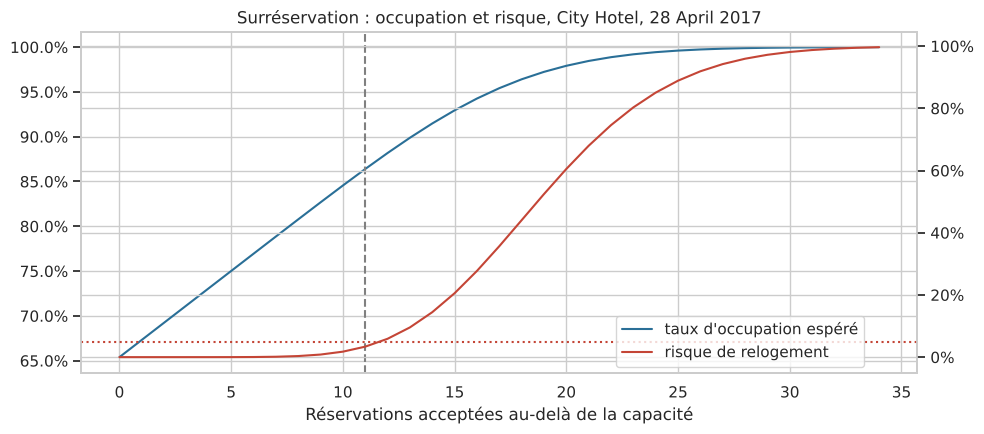

In [15]:
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(plan["reservations_supplementaires"], plan["taux_occupation_espere"], color="#2a6f97", label="taux d'occupation espéré")
ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax2 = ax1.twinx()
ax2.plot(plan["reservations_supplementaires"], plan["prob_au_moins_un_reloge"], color="#c44536", label="risque de relogement")
ax2.axhline(0.05, color="#c44536", ls=":")
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax1.axvline(k, color="grey", ls="--")
ax1.set_xlabel("Réservations acceptées au-delà de la capacité")
ax1.set_title(f"Surréservation : occupation et risque, City Hotel, {d_} {m_} {y_}")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.15))
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "surreservation.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation :** pour le 28 avril 2017 au City Hotel, le modèle prévoit 11,8 annulations sur 34 réservations ; 13 ont réellement eu lieu, la prévision est donc réaliste. Sans surréservation, le taux d'occupation espéré n'est que de 65 %. En acceptant **11 réservations supplémentaires**, l'occupation espérée monte à **86 %**, avec un risque de devoir reloger au moins un client de 3,4 % (sous le niveau de 5 % choisi). Le niveau de risque accepté est une décision de l'hôtel : l'application Streamlit permet de le faire varier.

---
# Conclusion

| Question | Réponse tirée des données |
|---|---|
| Quand les clients annulent-ils ? | 46 % des annulations sans dépôt ont lieu dans le dernier mois avant l'arrivée |
| Quelle part des chambres est revendue ? | de 61 % (dernière semaine) à 86 % (plus de 3 mois) |
| Combien les annulations coûtent-elles ? | 13,1 M€ brut, mais **3,0 M€ net** (11,7 % du revenu réalisé) ; 53 % de la perte nette vient du dernier mois |
| L'acompte dissuade-t-il d'annuler ? | impossible à mesurer avec ces données (association faussée par les blocs d'agences) : il faut un test A/B |
| Que rapporterait un acompte ? | au seuil F0,5, de 44 % à 140 % de la perte nette (510 203 € sur le test) selon la politique, en touchant 7,5 % des clients fidèles. F2 récupère plus (78 % à 206 %) mais touche 34,4 % des fidèles : avec 20 % du séjour, il rapporte plus tant que moins de 9,4 % des fidèles renoncent, F0,5 au-delà |
| Que faire pour chaque réservation ? | rien (risque faible), relance sans engagement (modéré), acompte et surréservation (élevé) |
| Combien surréserver ? | exemple : 11 réservations de plus, occupation de 65 % à 86 % pour un risque de relogement de 3,4 % |

**Recommandation.** Réserver l'acompte aux réservations à **risque élevé** (seuil F0,5), avec une politique **remboursable jusqu'à 30 jours** avant l'arrivée : elle vise la perte la plus coûteuse (les annulations tardives) et ménage les clients qui ne veulent pas s'engager longtemps à l'avance. Avant de la généraliser, la tester sur un échantillon tiré au hasard pour mesurer le taux de fuite réel.

**Limites.** La capacité des hôtels est estimée ; le taux de revente suppose que toutes les annulations d'une même nuit sont traitées de la même façon ; les résultats des sections 5 à 7 portent sur l'ensemble de test (20 % des réservations).